# 🔧 Config

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
import numpy as np

# custom modules
import data_loader
import data_visualizer

In [2]:
PATH_DATA ='data/raw/Telco_customer_churn.xlsx'

FIGSIZE = (12, 6)

SEED = 4586

# 📝 Definição de problema e escopo (CRISP-DM)
## Business Understanding
> - ❔ A diretoria precisa de um modelo preditivo de churn que **classifique clientes** com risco de cancelamento

### ✅ Critérios de sucesso
> - 🎯 Reduzir em 20% a taxa de churn trimestral, identificando clientes em risco com **antecedência** para ações de retenção
> - 💡**Interpretabilidade** - O modelo deverá ser utilizável e explicável para usuários sem conhecimento tecnológico aprofundado
> - ✅ Compliance LGPD

#### 📈 KPI
> - 🎯 Taxa de Churn

#### 📈 Dados técnicos
> - 🎯 O modelo deverá nos retornar uma classificação binária: se está em risco de churn, ou não
> - 📈 Recall >= 0.80

### 👥 Recursos
> - 👥 1 Engenheiro
> - 💻 5000+ registros para análise
> - 🛜 Infraestrutura simples FastAPI
> - 👥 Envolvimento Stakeholders: Suporte técnico, CRM e Call Center

### ❗ Restrições
> - ❗ Temos 7000+ registros
> - 🗺️ O modelo terá sua performance garantida apenas dentro da região geográfica abrangida na base de dados
> - 🏬 O modelo terá sua performance garantida apenas com clientes dessa instituição

### 📅 Cronograma
> - 📅 O modelo deverá estar pronto até 19/01/2027

### 🛠️ Ferramentas
> - 🐍 Python (pandas, scikit-learn)

### 🔧 Manutenção
> - ⌚ O modelo deve ser re-treinado e testado a cada trimestre

### 📓 Entrega esperada
> - 🏆 Um modelo exposto via FastAPI que entrega classificações à dados fornecidos, a ser entregue para a equipe de CRM
> - ❌**Não** será desenvolvido a estrutura para rodar o modelo automaticamente 

# 📈 Carregamento dos dados
Checagem inicial dos dados

Colunas descritas no [Kaggle](https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset):


| Value | Description | Options |
| --- | --- | --- |
| **CustomerID** | A unique ID that identifies each customer. | - |
| **Count** | A value used in reporting/dashboarding to sum up<br>the number of customers in a filtered set. | - |
| **Country** | The country of the customer’s primary residence. | - |
| **State** | The state of the customer’s primary residence. | - |
| **City** | The city of the customer’s primary residence. | - |
| **Zip Code** | The zip code of the customer’s primary residence. | - |
| **Lat Long** | The combined latitude and longitude of the customer’s primary residence. | - |
| **Latitude** | The latitude of the customer’s primary residence. | - |
| **Longitude** | The longitude of the customer’s primary residence. | - |
| **Gender** | The customer’s gender | Male, Female |
| **Senior Citizen** | Indicates if the customer is 65 or older | Yes, No |
| **Partner** | Indicate if the customer has a partner | Yes, No |
| **Dependents** | Indicates if the customer lives with any dependents | Yes, No.<br>Dependents could be children,<br>parents, grandparents, etc. |
| **Tenure Months** | Indicates the total amount of months that the customer has been<br>with the company by the end of the quarter specified above. | - |
| **Phone Service** | Indicates if the customer subscribes to home phone service<br>with the company | Yes, No |
| **Multiple Lines** | Indicates if the customer subscribes to multiple<br>telephone lines with the company | Yes, No |
| **Internet Service** | Indicates if the customer subscribes to<br>Internet service with the company | No, DSL, Fiber Optic, Cable. |
| **Online Security** | Indicates if the customer subscribes to an additional<br>online security service provided by the company | Yes, No |
| **Online Backup** | Indicates if the customer subscribes to an additional<br>online backup service provided by the company | Yes, No |
| **Device Protection** | Indicates if the customer subscribes to an additional<br>device protection plan for their Internet equipment provided by the company | Yes, No |
| **Tech Support** | Indicates if the customer subscribes to an additional<br>technical support plan from the company with reduced wait times | Yes, No |
| **Streaming TV** | Indicates if the customer uses their Internet service<br>to stream television programing from a third party provider | Yes, No.<br>The company does not charge<br>an additional fee for this service. |
| **Streaming Movies** | Indicates if the customer uses their Internet service<br>to stream movies from a third party provider | Yes, No.<br>The company does not charge<br>an additional fee for this service. |
| **Contract** | Indicates the customer’s current contract type | Month-to-Month, One Year, Two Year. |
| **Paperless Billing** | Indicates if the customer has chosen paperless billing | Yes, No |
| **Payment Method** | Indicates how the customer pays their bill | Bank Withdrawal, Credit Card, Mailed Check |
| **Monthly Charge** | Indicates the customer’s current total monthly charge for all their services from the company. | - |
| **Total Charges** | Indicates the customer’s total charges, calculated to the end of the quarter specified above. | - |
| **Churn Label** | - | Yes = the customer left the company this quarter.<br>No = the customer remained with the company.<br>Directly related to Churn Value. |
| **Churn Value** | - | 1 = the customer left the company this quarter.<br>0 = the customer remained with the company.<br>Directly related to Churn Label. |
| **Churn Score** | A value from 0-100 that is calculated using the predictive tool IBM SPSS Modeler.<br>The model incorporates multiple factors known to cause churn.<br>The higher the score, the more likely the customer will churn. | - |
| **CLTV** | Customer Lifetime Value.<br>A predicted CLTV is calculated using corporate formulas and existing data.<br>The higher the value, the more valuable the customer.<br>High value customers should be monitored for churn. | - |
| **Churn Reason** | A customer’s specific reason for leaving the company. Directly related to Churn Category. | - |

In [3]:
df = data_loader.load_churn_data(PATH_DATA)

df.sample(n=5,random_state=SEED)

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
5645,4903-CNOZC,1,United States,California,La Canada Flintridge,91011,"34.234912, -118.153729",34.234912,-118.153729,Male,...,One year,No,Credit card (automatic),70.90,1964.6,No,0,29,2064,NaN
5859,4049-ZPALD,1,United States,California,Forest Falls,92339,"34.067699, -116.903891",34.067699,-116.903891,Female,...,Two year,Yes,Bank transfer (automatic),99.00,6375.8,No,0,68,5483,NaN
1101,4088-YLDSU,1,United States,California,Redwood City,94062,"37.410567, -122.297152",37.410567,-122.297152,Male,...,One year,Yes,Electronic check,104.15,5743.05,Yes,1,86,4369,Competitor had better devices
594,1583-IHQZE,1,United States,California,Camarillo,93010,"34.227846, -119.079903",34.227846,-119.079903,Male,...,Month-to-month,Yes,Mailed check,112.95,1384.75,Yes,1,97,3965,Attitude of support person
4773,4537-CIBHB,1,United States,California,Arvin,93203,"35.116307, -118.817644",35.116307,-118.817644,Female,...,One year,No,Mailed check,20.25,172.35,No,0,48,4272,NaN


Formatando colunas

In [4]:
df.columns = data_loader.format_column_names(list(df.columns))

df.columns

Index(['customerid', 'count', 'country', 'state', 'city', 'zip_code',
       'lat_long', 'latitude', 'longitude', 'gender', 'senior_citizen',
       'partner', 'dependents', 'tenure_months', 'phone_service',
       'multiple_lines', 'internet_service', 'online_security',
       'online_backup', 'device_protection', 'tech_support', 'streaming_tv',
       'streaming_movies', 'contract', 'paperless_billing', 'payment_method',
       'monthly_charges', 'total_charges', 'churn_label', 'churn_value',
       'churn_score', 'cltv', 'churn_reason'],
      dtype='str')

In [5]:
df[['churn_label', 'churn_value', 'churn_score', 'churn_reason']].sample(5, random_state=SEED)

,churn_label,churn_value,churn_score,churn_reason
5645,No,0,29,NaN
5859,No,0,68,NaN
1101,Yes,1,86,Competitor had better devices
594,Yes,1,97,Attitude of support person
4773,No,0,48,NaN


In [6]:
df[['latitude', 'longitude', 'lat_long']].sample(5, random_state=SEED)

,latitude,longitude,lat_long
5645,34.234912,-118.153729,"34.234912, -118.153729"
5859,34.067699,-116.903891,"34.067699, -116.903891"
1101,37.410567,-122.297152,"37.410567, -122.297152"
594,34.227846,-119.079903,"34.227846, -119.079903"
4773,35.116307,-118.817644,"35.116307, -118.817644"


In [7]:
data : dict = {'column':[],'unique_values':[],'missing_values':[]}

for col in df.columns:
    unique_values_count : int = df[col].nunique()
    missing_values_count : int = df[col].isna().sum()

    data['column'].append(col)
    data['unique_values'].append(unique_values_count)
    data['missing_values'].append(missing_values_count)

df_value_data = pd.DataFrame(
    data=data
).set_index('column')

df_value_data

,unique_values,missing_values
column,,
customerid,7043,0
count,1,0
country,1,0
state,1,0
city,1129,0
zip_code,1652,0
lat_long,1652,0
latitude,1652,0
longitude,1651,0


Temos dados de apenas um país e estado. O modelo portanto só terá garantia de qualidade dentro desses parâmetros, e os dados de latitude e longitude estão dentro desses limites.

In [8]:
country : str = df['country'].values[0]
state : str = df['state'].values[0]

print(f'We only have data froun {state.upper()}, {country.upper()}')

We only have data froun CALIFORNIA, UNITED STATES


Separando as colunas em categorias...
## Categorização de colunas

In [9]:
binary_candidates = df_value_data[df_value_data['unique_values'] == 2].index
df[binary_candidates].head()

,gender,senior_citizen,partner,dependents,phone_service,paperless_billing,churn_label,churn_value
0,Male,No,No,No,Yes,Yes,Yes,1
1,Female,No,No,Yes,Yes,Yes,Yes,1
2,Female,No,No,Yes,Yes,Yes,Yes,1
3,Female,No,Yes,Yes,Yes,Yes,Yes,1
4,Male,No,No,Yes,Yes,Yes,Yes,1


In [10]:
# TRUE or FALSE
COLS_BINARY : list[str] = ['senior_citizen', 'partner', 'dependents', 'phone_service', 'paperless_billing']

COL_TARGET : str = 'churn_value'

# gender will be handled as a categorical

In [11]:
categorical_candidates = df_value_data[df_value_data['unique_values'] >= 2].index
categorical_candidates_narrowed = [candidate for candidate in categorical_candidates if candidate not in COLS_BINARY]
df_categorical_candidates = df[categorical_candidates_narrowed].head().T
df_categorical_candidates['unique_values'] = 0
for i in df_categorical_candidates.index:
    df_categorical_candidates.loc[i, 'unique_values'] = df_value_data.loc[i, 'unique_values']
df_categorical_candidates

,0,1,2,3,4,unique_values
customerid,3668-QPYBK,9237-HQITU,9305-CDSKC,7892-POOKP,0280-XJGEX,7043
city,Los Angeles,Los Angeles,Los Angeles,Los Angeles,Los Angeles,1129
zip_code,90003,90005,90006,90010,90015,1652
lat_long,"33.964131, -118.272783","34.059281, -118.30742","34.048013, -118.293953","34.062125, -118.315709","34.039224, -118.266293",1652
latitude,33.964131,34.059281,34.048013,34.062125,34.039224,1652
longitude,-118.272783,-118.30742,-118.293953,-118.315709,-118.266293,1651
gender,Male,Female,Female,Female,Male,2
tenure_months,2,2,8,28,49,73
multiple_lines,No,No,Yes,Yes,Yes,3
internet_service,DSL,Fiber optic,Fiber optic,Fiber optic,Fiber optic,3


In [12]:
binary_with_exception_candidates = df_value_data[df_value_data['unique_values'].between(3, 4)].index

for candidate in binary_with_exception_candidates:
    print(df[candidate].value_counts())
    print()

multiple_lines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

internet_service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

online_security
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

online_backup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

device_protection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

tech_support
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

streaming_tv
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64

streaming_movies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64

contract
Month-to-mont

In [13]:
df_categorical_candidates.index

Index(['customerid', 'city', 'zip_code', 'lat_long', 'latitude', 'longitude',
       'gender', 'tenure_months', 'multiple_lines', 'internet_service',
       'online_security', 'online_backup', 'device_protection', 'tech_support',
       'streaming_tv', 'streaming_movies', 'contract', 'payment_method',
       'monthly_charges', 'total_charges', 'churn_label', 'churn_value',
       'churn_score', 'cltv', 'churn_reason'],
      dtype='str')

Colocaremos em uma categoria separada as colunas binárias que tem uma "terceira opção", pois dependem de uma coluna externa para serem aplicáveis (por exemplo, só se pode ter múltiplas linhas de telefone se o cliente assina o serviço de telefone)

In [14]:
# data within a defined set of expected results
COLS_CATEGORICAL : list[str] = ['gender', 'internet_service', 'contract', 'payment_method', 'city']

# TRUE or FALSE with a 'non-applicable' option, that depend on another column
COLS_DEPENDANT_BINARIES : list[str] = ['multiple_lines', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies']

col_dependencies : dict = {
    'multiple_lines':'phone_service',
    'online_security':'internet_service',
    'online_backup':'internet_service',
    'device_protection':'internet_service',
    'tech_support':'internet_service', 
    'streaming_tv':'internet_service',
    'streaming_movies':'internet_service'
}

# numerical data
COLS_NUMERICAL : list[str] = ['latitude', 'longitude', 'tenure_months', 'cltv', 'total_charges', 'monthly_charges']

In [15]:
print(f'TODOS as contagens de valores')
print('='*10)
for col in col_dependencies.keys():
    display(df[[col, col_dependencies.get(col)]].value_counts())

print(f'\nContagens de valores onde a dependência é NÃO')
print('='*10)
for col in col_dependencies.keys():
    display(df[[col, col_dependencies.get(col)]].loc[df[col_dependencies.get(col)] == 'No'].value_counts())

TODOS as contagens de valores


multiple_lines    phone_service
No                Yes              3390
Yes               Yes              2971
No phone service  No                682
Name: count, dtype: int64

online_security      internet_service
No                   Fiber optic         2257
No internet service  No                  1526
No                   DSL                 1241
Yes                  DSL                 1180
                     Fiber optic          839
Name: count, dtype: int64

online_backup        internet_service
No                   Fiber optic         1753
No internet service  No                  1526
Yes                  Fiber optic         1343
No                   DSL                 1335
Yes                  DSL                 1086
Name: count, dtype: int64

device_protection    internet_service
No                   Fiber optic         1739
No internet service  No                  1526
Yes                  Fiber optic         1357
No                   DSL                 1356
Yes                  DSL                 1065
Name: count, dtype: int64

tech_support         internet_service
No                   Fiber optic         2230
No internet service  No                  1526
No                   DSL                 1243
Yes                  DSL                 1178
                     Fiber optic          866
Name: count, dtype: int64

... (6 outputs left out)

device_protection    internet_service
No internet service  No                  1526
Name: count, dtype: int64

tech_support         internet_service
No internet service  No                  1526
Name: count, dtype: int64

streaming_tv         internet_service
No internet service  No                  1526
Name: count, dtype: int64

streaming_movies     internet_service
No internet service  No                  1526
Name: count, dtype: int64

## Dataframe categorizado

In [16]:
print(f'The original DataFrame has {len(df.columns)} columns')
print(f'We have categorized {len(COLS_BINARY) + len(COLS_NUMERICAL) + len(COLS_CATEGORICAL) + len(COLS_DEPENDANT_BINARIES) + len([COL_TARGET])} of them')

print(f'\nRemaining columns\n{[col for col in df.columns if col not in COLS_BINARY + COLS_NUMERICAL + COLS_CATEGORICAL + COLS_DEPENDANT_BINARIES + [COL_TARGET]]}')

The original DataFrame has 33 columns
We have categorized 24 of them

Remaining columns
['customerid', 'count', 'country', 'state', 'zip_code', 'lat_long', 'churn_label', 'churn_score', 'churn_reason']


Na fase de treinamento, descartaremos as colunas redundantes ou irrelevantes para nossa análise, mantendo apenas as que categorizamos. 

In [17]:
# these columns will be discarded once we enter the ML phase
COLS_DISCARD : list[str] = ['customerid', 'count', 'country', 'state', 'zip_code', 'lat_long', 'churn_label', 'churn_score', 'churn_reason']

# joining columns in desired order
cols_to_analyze : list[str] = [COL_TARGET] + COLS_NUMERICAL + COLS_CATEGORICAL + COLS_BINARY + COLS_DEPENDANT_BINARIES + COLS_DISCARD

df = df[cols_to_analyze]

print(df.shape)
print(df.columns)

(7043, 33)
Index(['churn_value', 'latitude', 'longitude', 'tenure_months', 'cltv',
       'total_charges', 'monthly_charges', 'gender', 'internet_service',
       'contract', 'payment_method', 'city', 'senior_citizen', 'partner',
       'dependents', 'phone_service', 'paperless_billing', 'multiple_lines',
       'online_security', 'online_backup', 'device_protection', 'tech_support',
       'streaming_tv', 'streaming_movies', 'customerid', 'count', 'country',
       'state', 'zip_code', 'lat_long', 'churn_label', 'churn_score',
       'churn_reason'],
      dtype='str')


# 🔍 EDA

In [18]:
def plot_value_counts(
        data : pd.DataFrame,
        fig_title : str = '',
        figsize : tuple = (16, 6),
        ncols : int = 3,
        max_categories : int = 10,
        sort_alphabetically : bool = False,
        title_suffix : str = 'Clientes por ',
        xlabel : str = 'Qtd'
):
    """Plots columns' value counts in horizontal bar charts
    
    Parameters
    ---
        data : pd.Dataframe
        figsize : tuple, default (16, 6)
        ncols : int
        max_categories : int
        sort_alphabetically : bool
            If True, the category axis will be sorter alphabetically
        title_suffix : str, default 'Clientes por '
            Text that will be concatenated before the column name in the graph's title
        xlabel : str, default 'Qtd'
    
    Returns
    ---
        fig, axs
    """
    nrows : int = int(np.ceil(len(data.columns) / ncols) )

    cols = [str(col) for col in data.columns]

    fig, axs = plt.subplots(figsize=figsize, ncols=ncols, nrows=nrows)

    if nrows == 1 and ncols == 1:
        value_labels = [str(label) for label in data[data.columns[0]].value_counts().index]
        value_counts_data = data.value_counts().values

        if sort_alphabetically:
            sorted_pairs = sorted(zip(value_labels, value_counts_data))
            value_labels, value_counts = zip(*sorted_pairs)

        # if there are too many categories to plot
        if len(value_labels) > max_categories:
            axs.barh(y = value_labels[:max_categories], width = value_counts[:10])
        else:
            axs.barh(y = value_labels, width = value_counts)

        axs.set_title(f'{title_suffix}{cols[0]}')
        axs.set_xlabel(xlabel)

    else:
        for col, ax in zip(cols, axs.flatten()):
            value_labels = [str(label) for label in data[col].value_counts().index]

            value_counts = data[col].value_counts().values

            if sort_alphabetically:
                sorted_pairs = sorted(zip(value_labels, value_counts))
                value_labels, value_counts = zip(*sorted_pairs)

            # if there are too many categories to plot
            if len(value_labels) > max_categories:
                ax.barh(y = value_labels[:max_categories], width = value_counts[:10])
            else:
                ax.barh(y = value_labels, width = value_counts)

            ax.set_title(f'{title_suffix}{col}')
            ax.set_xlabel(xlabel)

    fig.suptitle(fig_title)
    plt.tight_layout()
    return fig, axs

In [19]:
label_color_dict = {
    'Yes':"#d86902",
    'No':"#6195d1",
    'No internet service':'gray',
    'No phone service': 'gray'
}

('No', 'Yes')
Index(['No', 'Yes'], dtype='str', name='senior_citizen')
('No', 'Yes')
Index(['No', 'Yes'], dtype='str', name='partner')
('No', 'Yes')
Index(['No', 'Yes'], dtype='str', name='dependents')
('No', 'Yes')
Index(['Yes', 'No'], dtype='str', name='phone_service')
('No', 'Yes')
Index(['Yes', 'No'], dtype='str', name='paperless_billing')
('No', 'No phone service', 'Yes')
Index(['No', 'Yes', 'No phone service'], dtype='str', name='multiple_lines')
('No', 'No internet service', 'Yes')
Index(['No', 'Yes', 'No internet service'], dtype='str', name='online_security')
('No', 'No internet service', 'Yes')
Index(['No', 'Yes', 'No internet service'], dtype='str', name='online_backup')
('No', 'No internet service', 'Yes')
Index(['No', 'Yes', 'No internet service'], dtype='str',
      name='device_protection')
('No', 'No internet service', 'Yes')
Index(['No', 'Yes', 'No internet service'], dtype='str', name='tech_support')
('No', 'No internet service', 'Yes')
Index(['No', 'Yes', 'No interne

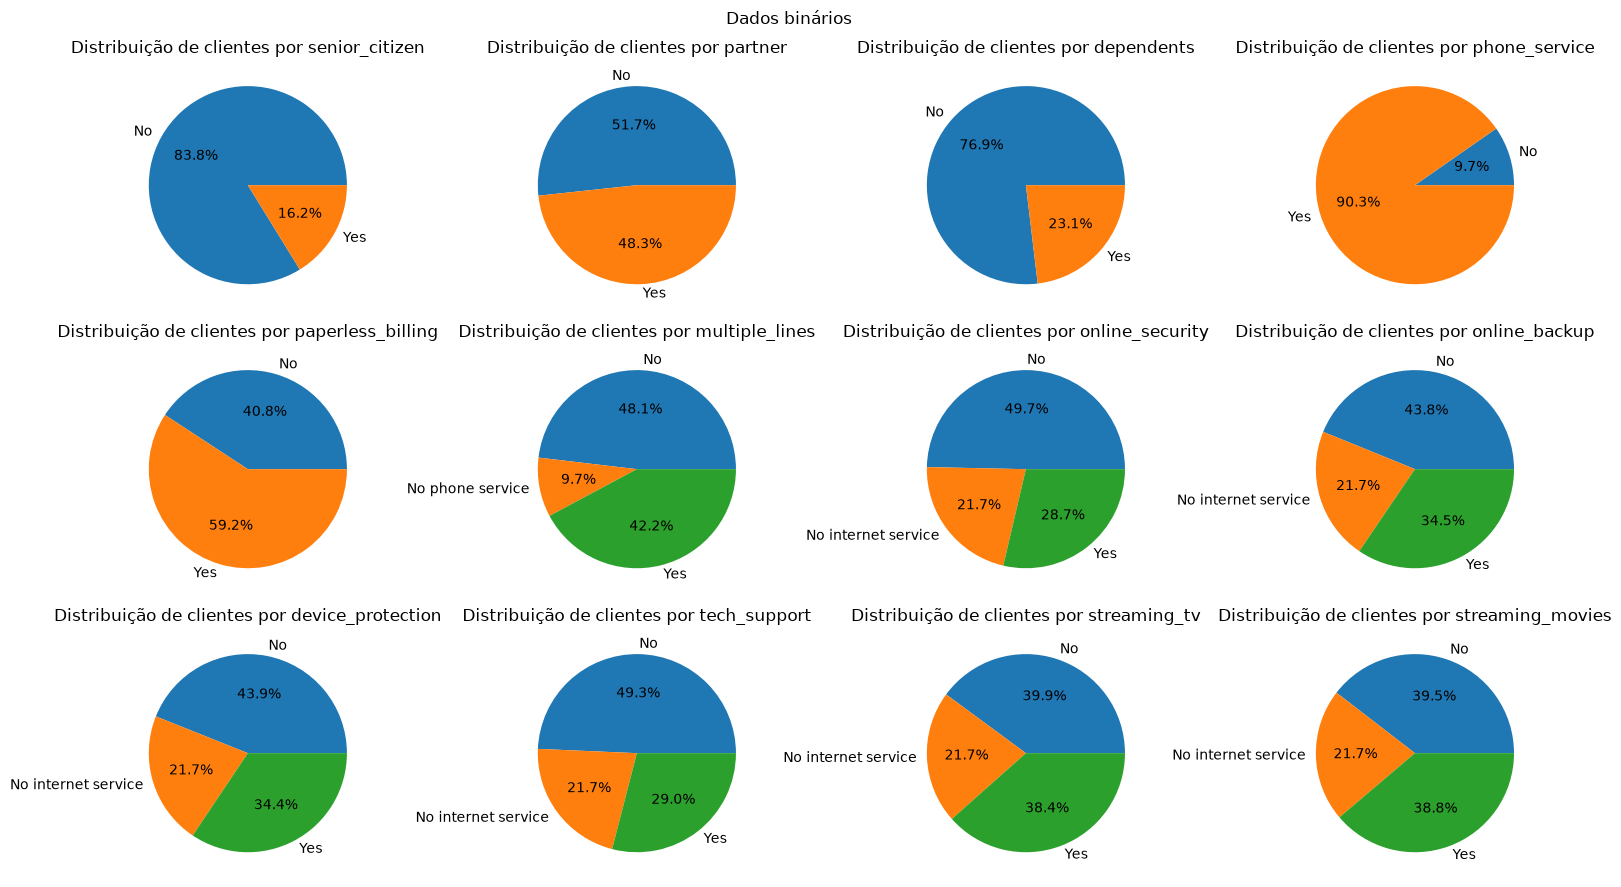

In [20]:
data_visualizer.plot_value_counts_pie(df[COLS_BINARY + COLS_DEPENDANT_BINARIES], ncols=4,fig_title='Dados binários', figsize=(16, 9), sort_alphabetically=True, color_dict=label_color_dict)
plt.show()

## Colunas categóricas

In [ ]:
plot_value_counts(df[COLS_BINARY + COLS_DEPENDANT_BINARIES], ncols=4, fig_title='Dados binários', figsize=(16, 9), sort_alphabetically=True)

plt.show()

In [ ]:
fig, axs = plt.subplots(
    figsize=(16, 6),
    ncols=4,
    nrows=3)


labels : list | pd.Index = df['senior_citizen'].value_counts().index
axs.flatten()[0].pie(
    df['senior_citizen'].value_counts(),
    labels = labels,
    autopct='%1.1f%%'
)

plt.show()

>- A maioria dos clientes não são idosos (>65 anos)
>- Cerca de metade dos clientes são parceiros
>- A maioria dos clientes não têm dependentes
>- A maioria dos clientes utilizam do serviço de telefone da empresa
>- Uma moderada maioria dos clientes utilizam pagamento sem papel
>- Dos clientes que contratam o serviço de telefone, uma leve maioria deles não utilizam o serviço de múltiplas linhas
>- Dos clientes que contratam o serviço de internet, a maioria não contrata o serviço de segurança
>- Dos clientes que contratam o serviço de internet, uma leve maioria não contrata o serviço de backup
>- Dos clientes que contratam o serviço de internet, uma leve maioria não contrata o serviço de proteção de dispositivo
>- Dos clientes que contratam o serviço de internet, a maioria não contrata 

In [ ]:
plot_value_counts(df[['churn_reason']], fig_title='Razão de cancelamento',ncols=1)
plt.show()

# Tratamento de dados

## Padronização de valores binários
'Yes' e 'No' serão convertidos para 0 (False) e 1 (True).
Valores com exceção ("sem internet") serão convertidos para -1.

In [ ]:
DICT_BINARY : dict = {
    'Yes' : 1,
    'No' : 0
}

# implement
ORDER_BINARY : dict = {
    1:1,
    0:2,
    -1:3
}

In [ ]:
plot_value_counts(df[COLS_BINARY + COLS_DEPENDANT_BINARIES], figsize=(16, 12), sort_alphabetically=True)
plt.show()

In [ ]:
df[COLS_BINARY + COLS_DEPENDANT_BINARIES] = df[COLS_BINARY + COLS_DEPENDANT_BINARIES].map(lambda x: DICT_BINARY.get(x, -1))

In [ ]:
df.head(2).T

In [ ]:
plot_value_counts(df[COLS_BINARY], sort_alphabetically=True)
plt.show()

## Padronização de valores numéricos

## Padronização de texto (valores categóricos)